# ENEM 2024 · Alvo por classes do Sisu — a redação no nível de quem passa

**Ideia:** em vez de prever a nota da redação (0–1000), prever em que **classe** ela está, usando uma régua
externa e com significado prático: as **notas de corte do Sisu 2025**, a seleção que usou as notas do ENEM 2024.

| Classe | Regra | Nota da redação |
|---|---|---|
| **Competitiva** | alcança a redação **mediana** de quem passaria em pelo menos **metade** dos cursos | calculado abaixo |
| **Intermediária** | alcança o **1º quartil** da redação de quem passaria em pelo menos **10%** dos cursos | calculado abaixo |
| **Baixa** | abaixo disso | |

**Por que não usar a nota de corte direto?** A nota de corte do Sisu é a **média ponderada das cinco provas**,
não a nota da redação. Não existe "nota de corte de redação". Por isso o caminho é:

1. pegar a nota de corte da **ampla concorrência** de cada curso e os **pesos** que o curso dá a cada prova;
2. nos resultados do ENEM 2024 (`RESULTADOS_2024`, que tem as cinco notas de cada participante), separar quem
   teria média ponderada acima do corte daquele curso — os **"qualificados"**;
3. olhar a **redação** desse grupo: a mediana e o 1º quartil dizem qual redação é típica de quem passa ali;
4. para cada nota de redação, contar em quantos % dos cursos ela alcança essa redação típica.

**Fontes:** `dados_sisu/sisu2025_ofertas_notas_corte.csv` (ver `dados_sisu/LEIA-ME.md`) e os microdados do ENEM 2024.

## 0 · Setup

In [1]:
import csv
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PASTA      = os.environ.get("ENEM_OUT", "data_processed")
ARQ_SISU   = os.path.join("dados_sisu", "sisu2025_ofertas_notas_corte.csv")
ARQ_RESULT = os.path.join("microdados_enem_2024", "microdados_enem_2024", "DADOS", "RESULTADOS_2024.csv")
SEED       = 42
AMOSTRA    = 250_000   # participantes usados para estimar a redação dos qualificados de cada curso
MIN_QUALIF = 30        # cursos com menos qualificados na amostra ficam sem estimativa

os.makedirs(PASTA, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

## 1 · As ofertas do Sisu 2025

Uma linha por oferta (curso + turno + campus + instituição). Ficamos com a nota de corte da
**ampla concorrência**: as modalidades de cota têm cortes menores e valem só para parte dos candidatos.
Ofertas sem nota de corte (sem inscritos suficientes) ficam de fora.

In [2]:
def num(s):
    return float(s) if s not in ("", None) else 0.0

ofertas = []
with open(ARQ_SISU, encoding="utf-8") as f:
    for r in csv.reader(f, delimiter=";"):
        corte = None
        for i in range(21, len(r), 5):                       # blocos de 5 campos por modalidade
            if r[i].strip() == "Ampla concorrência":
                corte, vagas = num(r[i + 2]), int(num(r[i + 1]))
                break
        if not corte:
            continue
        ofertas.append(dict(
            codigo=r[0], curso=r[1].strip(), grau=r[2], turno=r[3], campus=r[5], municipio=r[6], uf=r[7],
            ies=r[8], sigla_ies=r[9],
            peso_cn=num(r[10]), peso_ch=num(r[11]), peso_lc=num(r[12]), peso_mt=num(r[13]), peso_red=num(r[14]),
            min_cn=num(r[15]), min_ch=num(r[16]), min_lc=num(r[17]), min_mt=num(r[18]), min_red=num(r[19]),
            media_minima=num(r[20]), vagas_ac=vagas, nota_corte_ac=corte))

cursos = pd.DataFrame(ofertas)
print(f"ofertas com nota de corte na ampla concorrência: {len(cursos):,}")
cursos["nota_corte_ac"].describe().round(1)

ofertas com nota de corte na ampla concorrência: 6,393


count    6393.0
mean      649.9
std        66.0
min       230.2
25%       606.4
50%       653.2
75%       694.7
max       856.4
Name: nota_corte_ac, dtype: float64

## 2 · As cinco notas dos participantes do ENEM 2024

`RESULTADOS_2024` não se liga ao questionário (não tem `NU_INSCRICAO`), mas tem as cinco notas de cada
participante — é o que precisamos para simular quem passaria em cada curso. Ficam os que fizeram as quatro
provas objetivas e tiveram a redação corrigida sem problema (`TP_STATUS_REDACAO == 1`), como exige o Sisu.
Uma amostra aleatória de 250 mil basta para estimar medianas.

In [3]:
COLS = ["TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT",
        "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "TP_STATUS_REDACAO", "NU_NOTA_REDACAO"]
res = pd.read_csv(ARQ_RESULT, sep=";", encoding="latin1", usecols=COLS, dtype="float32")

presentes = (res[COLS[:4]] == 1).all(axis=1) & (res["TP_STATUS_REDACAO"] == 1)
validos = res.loc[presentes, COLS[4:8] + ["NU_NOTA_REDACAO"]].dropna()
redacoes_2024 = res["NU_NOTA_REDACAO"].dropna().to_numpy()   # todas as redações com nota, inclusive zeradas
print(f"participantes: {len(res):,} | com as 5 notas válidas: {len(validos):,} | redações com nota: {len(redacoes_2024):,}")

amostra = validos.sample(min(AMOSTRA, len(validos)), random_state=SEED)
NOTAS = amostra.to_numpy(dtype="float64")   # colunas: CN, CH, LC, MT, redação (mesma ordem dos pesos)
media_simples = NOTAS.mean(axis=1)
redacao = NOTAS[:, 4]
del res, validos

participantes: 4,332,944 | com as 5 notas válidas: 2,859,996 | redações com nota: 3,167,955


## 3 · A redação de quem passaria em cada curso

Para cada curso: média ponderada com os pesos dele, aplicação das notas mínimas e da média mínima, e então a
**mediana** e o **1º quartil** da redação de quem fica acima do corte. Ofertas com os mesmos pesos reaproveitam
a média ponderada, por isso o laço percorre as ofertas ordenadas pelos pesos.

In [4]:
PESOS   = ["peso_cn", "peso_ch", "peso_lc", "peso_mt", "peso_red"]
MINIMOS = ["min_cn", "min_ch", "min_lc", "min_mt", "min_red"]
W, M = cursos[PESOS].to_numpy(), cursos[MINIMOS].to_numpy()

mediana = np.full(len(cursos), np.nan)
p25     = np.full(len(cursos), np.nan)
acima   = np.zeros(len(cursos))
ultimo, media_pond = None, None
for k in sorted(range(len(cursos)), key=lambda k: tuple(W[k])):
    if tuple(W[k]) != ultimo:
        ultimo = tuple(W[k])
        media_pond = NOTAS @ W[k] / W[k].sum()
    passa = ((media_pond >= cursos["nota_corte_ac"].iat[k]) & (NOTAS >= M[k]).all(axis=1)
             & (media_simples >= cursos["media_minima"].iat[k]))
    acima[k] = passa.mean()
    if passa.sum() >= MIN_QUALIF:
        mediana[k] = np.median(redacao[passa])
        p25[k] = np.percentile(redacao[passa], 25)

cursos["pct_enem_acima_do_corte"] = (acima * 100).round(2)
cursos["mediana_redacao_qualificados"] = mediana
cursos["p25_redacao_qualificados"] = p25
print(f"cursos com estimativa: {np.isfinite(mediana).sum():,} de {len(cursos):,}")
cursos[["nota_corte_ac", "pct_enem_acima_do_corte",
        "mediana_redacao_qualificados", "p25_redacao_qualificados"]].describe().round(1)

cursos com estimativa: 6,391 de 6,393


,nota_corte_ac,pct_enem_acima_do_corte,mediana_redacao_qualificados,p25_redacao_qualificados
count,6393.0,6393.0,6391.0,6391.0
mean,649.9,18.0,877.8,819.7
std,66.0,16.3,47.7,72.6
min,230.2,0.0,660.0,540.0
25%,606.4,5.8,860.0,780.0
50%,653.2,13.3,880.0,840.0
75%,694.7,25.7,920.0,880.0
max,856.4,100.0,960.0,940.0


**Leitura:** no curso típico só cerca de 13% dos participantes do ENEM 2024 passariam do corte da ampla
concorrência, e a redação mediana desse grupo fica perto de 880. É por isso que dividir em cinco faixas de 20%
dos cursos não funciona: mais de 80% dos alunos cairiam na última letra.

## 4 · Da nota da redação para a % de cursos alcançados

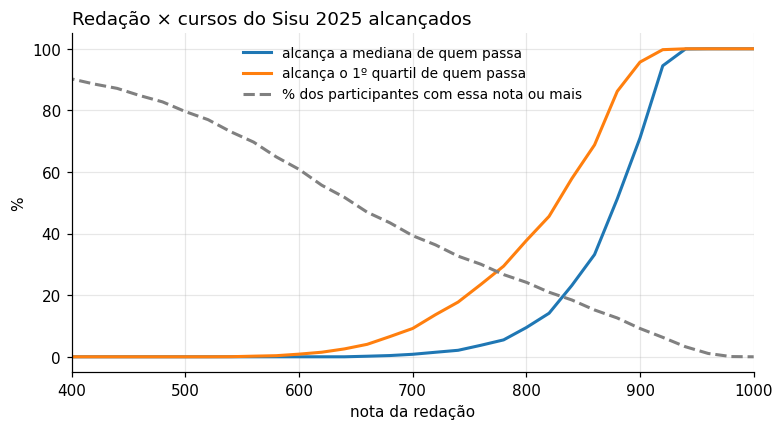

,nota_redacao,pct_cursos_mediana,pct_cursos_p25,pct_alunos_com_nota_maior_igual
30,600,0.0,0.9,60.9
31,620,0.0,1.5,55.7
32,640,0.0,2.6,51.8
33,660,0.2,4.1,46.9
34,680,0.4,6.6,43.5
35,700,0.8,9.2,39.3
36,720,1.5,13.7,36.4
37,740,2.1,17.8,32.7
38,760,3.7,23.5,30.0
39,780,5.5,29.4,26.7


In [5]:
med_ord = np.sort(mediana[np.isfinite(mediana)])
p25_ord = np.sort(p25[np.isfinite(p25)])
notas = np.arange(0, 1001, 20)                       # a redação do ENEM só assume múltiplos de 20
curva = pd.DataFrame({
    "nota_redacao": notas,
    "pct_cursos_mediana": np.searchsorted(med_ord, notas, side="right") / len(med_ord) * 100,
    "pct_cursos_p25": np.searchsorted(p25_ord, notas, side="right") / len(p25_ord) * 100,
    "pct_alunos_com_nota_maior_igual": [(redacoes_2024 >= n).mean() * 100 for n in notas],
})

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(curva.nota_redacao, curva.pct_cursos_mediana, lw=2, label="alcança a mediana de quem passa")
ax.plot(curva.nota_redacao, curva.pct_cursos_p25, lw=2, label="alcança o 1º quartil de quem passa")
ax.plot(curva.nota_redacao, curva.pct_alunos_com_nota_maior_igual, lw=2, ls="--", color="gray",
        label="% dos participantes com essa nota ou mais")
ax.set_xlabel("nota da redação"); ax.set_ylabel("%"); ax.set_xlim(400, 1000)
ax.legend(frameon=False, fontsize=9); ax.set_title("Redação × cursos do Sisu 2025 alcançados", loc="left")
plt.show()
curva[curva.nota_redacao.between(600, 960)].round(1)

## 5 · As três classes

In [6]:
def menor_nota(coluna, pct):
    # menor nota de redação que alcança a referência em pelo menos pct% dos cursos
    return int(curva.loc[curva[coluna] >= pct, "nota_redacao"].min())

LIM_COMPETITIVA   = menor_nota("pct_cursos_mediana", 50)
LIM_INTERMEDIARIA = menor_nota("pct_cursos_p25", 10)
CLASSES = ["Baixa", "Intermediária", "Competitiva"]
print(f"Intermediária: redação >= {LIM_INTERMEDIARIA} | Competitiva: redação >= {LIM_COMPETITIVA}")

def classe_sisu(nota):
    # nota da redação (0-1000) -> classe; NaN continua NaN
    return pd.cut(nota, bins=[-np.inf, LIM_INTERMEDIARIA, LIM_COMPETITIVA, np.inf],
                  labels=CLASSES, right=False)

dist = classe_sisu(pd.Series(redacoes_2024)).value_counts(normalize=True).reindex(CLASSES) * 100
print(dist.round(1).to_string())

Intermediária: redação >= 720 | Competitiva: redação >= 880
Baixa            63.6
Intermediária    23.8
Competitiva      12.6


O alvo continua desbalanceado (a classe Baixa tem a maioria), mas bem menos do que as cinco letras e cada
classe tem um significado concreto para o aluno. Na hora de modelar valem os cuidados da Sprint 5:
validação estratificada, `class_weight="balanced"` e métricas por classe (F1 macro, matriz de confusão) em vez
de acurácia.

## 6 · Gravação

In [7]:
cursos.sort_values(["uf", "sigla_ies", "curso", "turno"]).to_csv(
    os.path.join(PASTA, "sisu2025_cursos_redacao.csv"), index=False, sep=";", decimal=",", encoding="utf-8-sig")
pd.DataFrame({"classe": CLASSES, "nota_redacao_minima": [0, LIM_INTERMEDIARIA, LIM_COMPETITIVA],
              "pct_participantes_2024": dist.round(2).to_numpy()}).to_csv(
    os.path.join(PASTA, "limiares_classe_sisu.csv"), index=False, sep=";", decimal=",")
print(os.listdir(PASTA))

['enem2024_features_amostra_onehot.parquet', 'enem2024_features_ordinal.parquet', 'limiares_classe_sisu.csv', 'lista_features.csv', 'sisu2025_cursos_redacao.csv']


## Como usar nos outros notebooks

A classe é só uma faixa da nota da redação, então sai direto de `y_nota`, sem rodar este notebook de novo:

```python
lim = pd.read_csv(os.path.join(PASTA, "limiares_classe_sisu.csv"), sep=";", decimal=",")
cortes = lim["nota_redacao_minima"].tolist()[1:]          # [Intermediária, Competitiva]
base["y_classe_sisu"] = pd.cut(base["y_nota"], bins=[-np.inf, *cortes, np.inf],
                               labels=lim["classe"].tolist(), right=False)
```

**Vazamento:** a classe vem só da redação. Nenhuma coluna do conjunto de features (questionário, escola,
município) entra na sua definição, e os limiares são uma régua externa fixa (Sisu 2025), calculada uma vez e
não ajustada no conjunto de teste. Basta continuar sem usar notas de redação ou de competências como feature.